In [1]:
import sklearn as sk
import numpy as np
import pandas as pa
import matplotlib.pyplot as plt

1- Chargez les données (fichier *data.csv*).

In [2]:
data = pa.read_csv('data.csv')
data.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data.csv'

2- Définissez les variables X et y contenant respectivement les caractéristiques et les classes des exemples.

In [163]:
X =  data[['F1', 'F2', 'F3', 'F4']]
y = data.Classes


3- Combien y-a-t-il de classes? Quelle est la dimension des caractéristiques? Les classes sont-elles équilibrées?

In [164]:
print(data.Classes.unique())
print('nb classes uniques', len(data.Classes.unique()))
print('nb classe 0 : ', len(data[data.Classes==0]))
print('nb classe 1 : ', len(data[data.Classes==1]))
print('nb classe 2 : ', len(data[data.Classes==2]))
# Il y a 3 classes : 0, 1 et 2
# Les caractéristiques sont de dimension 4, étant donné qu'il y a 4 caractéristiques différentes (F1, F2, F3 et F4)
# Non, les classes ne sont pas équilibrées, il y a 126 classe 0, 999 classe 1 et 875 classe 2

[1 2 0]
nb classes uniques 3
nb classe 0 :  126
nb classe 1 :  999
nb classe 2 :  875


4- A partir de ces données, créez les ensembles d'entrainement (80% du total) et de test (20% du total).

In [122]:
from sklearn.model_selection import train_test_split

In [123]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2)

5- Commentez le résultat d'un classifieur Bayésien sur les données précédentes en expliquant la matrice de confusion. Toutes les classes sont-elles aussi bien prédites? L'accuracy est-elle une mesure pertinente de la qualité de ce classifieur?

Vous pouvez visualiser une matrice de confusion *cm* calculée avec la fonction *confusion_matrix* de sklearn en utilisant le code suivant. La variable *nb* est celle qui correspond au classifieur utilisé.

In [124]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)


GaussianNB()

In [125]:
y_pred = nb.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 20   0   5]
 [ 36 148   4]
 [ 10  23 154]]


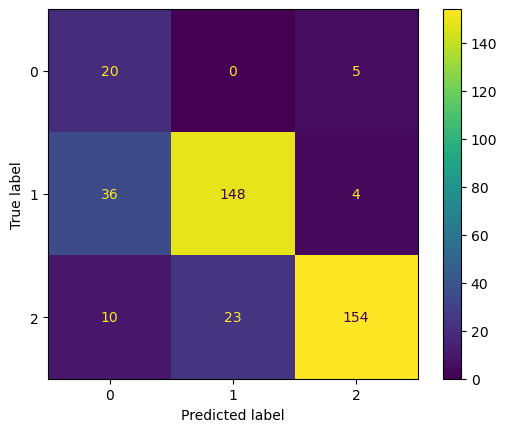

In [126]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=nb.classes_)
disp.plot()
plt.show()

6- De même commentez le résultat d'un classifieur Knn sur les données précédentes en expliquant la matrice de confusion.

In [127]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   F1       2000 non-null   float64
 1   F2       2000 non-null   float64
 2   F3       2000 non-null   float64
 3   F4       2000 non-null   float64
 4   Classes  2000 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 78.3 KB


In [128]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
print(X_train.describe())

                F1           F2           F3           F4
count  1500.000000  1500.000000  1500.000000  1500.000000
mean     -0.001906    -0.021539    -0.029208     0.057679
std       0.286980     1.018948     1.075171     0.954997
min      -0.986254    -3.348211    -3.410894    -2.530268
25%      -0.194152    -0.726339    -0.776767    -0.640050
50%       0.011821     0.055047     0.044325     0.050069
75%       0.200021     0.704047     0.720573     0.740219
max       0.824352     3.065357     3.321024     3.068731


In [129]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

KNeighborsClassifier()

[[  8  14   6]
 [  6 225   7]
 [  5  11 218]]


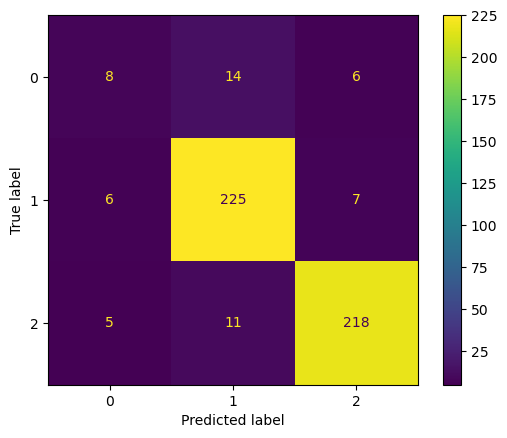

In [130]:
y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=nb.classes_)
disp.plot()
plt.show()

#Ici, la matrice de confusion est différente, mais beaucoup plus précise comme on peut le voir sur le nombre de vrai positif qui atteint 
# de biens plus grosses valeurs, et les vrai négatifs qui sont réduits (sauf pour certains, mais c'est minime)

7- Proposez une solution pour trouver une valeur de k (nombre de voisins) qui soit optimum. Expliquez votre démarche.

In [131]:
def best_model_search(X_train, X_test, y_train, y_test, n=10, patience=3):
    k = 1
    best_acc = 0
    best_model = None
    p = patience
    while k <n and p >0 :
        knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
        knn.fit(X_train, y_train)
        y_pred = knn.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)
        acc = np.sum(np.diag(cm))/np.sum(cm)
        print('k: ',k, '{:.2%}'.format(acc))
        if acc > best_acc:
            best_acc = acc
            best_model = knn
            p = patience + 1
        p = p -1
        k = k+1
    return best_model,k, best_acc

print(best_model_search(X_train, X_test, y_train, y_test))

# Démarche : On teste la différence entre attendu / vérité avec k nombre de voisins de 1 à 10, 
# La valeur de k qui a le plus haut pourcentage est le nombre de voisins à définir, ici 7 (90.80%)

k:  1 86.80%
k:  2 86.20%
k:  3 89.40%
k:  4 89.40%
k:  5 90.20%
k:  6 90.20%
k:  7 90.80%
k:  8 90.40%
k:  9 90.80%
(KNeighborsClassifier(metric='euclidean', n_neighbors=7), 10, 0.908)


8- On veut maintenant ajouter une étape de réduction de dimension à la classification du même jeu de données. On travaille dans un premier temps avec l'ACP. A quelles dimensions peut-on ramener les données? Quelle est la dimension que vous allez retenir et pourquoi ?

In [ ]:
# C'est un jeu de données de dimension 4 (4 différentes colonnes / caractéristiques), on peut amener ce jeu de données à un jeu de dimension 3 pour avoir un
# maximum de précision

In [132]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
z = scaler.fit_transform(X)



In [133]:
from sklearn.decomposition import PCA
acp = PCA()

In [134]:
coord = acp.fit_transform(z)
print(acp.n_components_)
print(acp.explained_variance_ratio_)

4
[7.55984755e-01 2.44015245e-01 2.01686508e-16 2.24271866e-17]


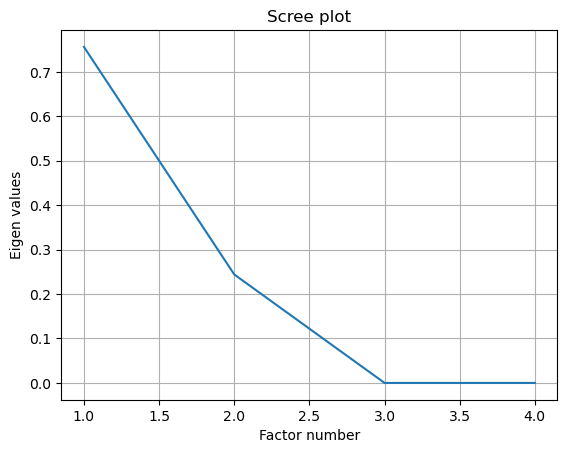

In [135]:
%matplotlib inline
plt.grid()
plt.plot(np.arange(1,acp.n_components_+1),acp.explained_variance_ratio_) 
plt.title("Scree plot") 
plt.ylabel("Eigen values") 
plt.xlabel("Factor number") 
plt.show()

9- Testez un classifieur Bayésien sur les données précédentes avec une réduction de dimension basée sur l'ACP.

In [136]:
nb = GaussianNB()
print('Sans réduction :')
X_train, X_test, y_train, y_test = train_test_split(X, y)
%timeit nb.fit(X_train, y_train)
print(X_train.shape)
y_pred = nb.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Sans réduction :
1.33 ms ± 19.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
(1500, 4)
accuracy:  0.796


In [137]:
print('Après réduction :')

nb = GaussianNB()

scaler.fit(X_train)
z = scaler.transform(X_train)
p = 3
acp = PCA(n_components=p)
X_train_proj = acp.fit_transform(z)
print(X_train_proj.shape) 
%timeit nb.fit(X_train_proj, y_train)

z = scaler.transform(X_test)
X_test_proj = acp.transform(z)
y_pred = nb.predict(X_test_proj)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Après réduction :
(1500, 3)
801 μs ± 2.73 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
accuracy:  0.902


In [ ]:
# On voit qu'on gagne environ 9-11% d'accuracy (ça dépend du 80-20) avec 3 caractéristiques au lieu de 4

10- Testez un classifieur Knn sur les données précédentes avec une réduction de dimension basée sur l'ACP.

In [138]:
knn = KNeighborsClassifier()
print('Sans réduction :')
X_train, X_test, y_train, y_test = train_test_split(X, y)
%timeit knn.fit(X_train, y_train)
print(X_train.shape)
y_pred = knn.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Sans réduction :
1.49 ms ± 17.5 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
(1500, 4)
accuracy:  0.9


In [139]:
print('Après réduction :')

knn = KNeighborsClassifier()

scaler.fit(X_train)
z = scaler.transform(X_train)
p = 3
acp = PCA(n_components=p)
X_train_proj = acp.fit_transform(z)
print(X_train_proj.shape) 
%timeit knn.fit(X_train_proj, y_train)

z = scaler.transform(X_test)
X_test_proj = acp.transform(z)
y_pred = knn.predict(X_test_proj)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

# Ici, ça donne le même résultat avec 4 comme 3 caractéristiques, (2 aussi, mais environ 50% d'accuracy pour une réduction à 1 dimension)

Après réduction :
(1500, 3)
855 μs ± 4.22 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
accuracy:  0.9


11- On travaille maintenant avec la LDA. Si on utilise les paramètres par défaut de *LinearDiscriminant Analysis*, quelle sera la dimension des données réduites? Testez un classifieur Baysien et un classifieur knn sur les données précédentes avec une réduction en dimension basée sur la LDA.

In [140]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis()


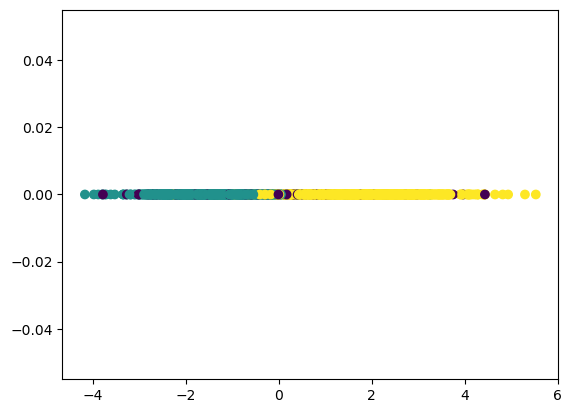

In [141]:
X_lda = lda.fit_transform(X,y)
lda.explained_variance_ratio_
plt.scatter(X_lda[:,0], np.zeros(X_lda.shape[0]), c=y)
# ça réduit à une dimension de 1.

In [ ]:
# NB

In [142]:
X_train, X_test, y_train, y_test = train_test_split(X, y)
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

nb = GaussianNB()
print('Sans réduction :')
%timeit nb.fit(X_train, y_train)
y_pred = nb.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Sans réduction :
1.31 ms ± 4.58 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
accuracy:  0.78


In [143]:
lda = LinearDiscriminantAnalysis()
X_train_lda = lda.fit_transform(X_train, y_train)
X_test_lda = lda.transform(X_test)
nb = GaussianNB()
print('Après réduction :')
%timeit nb.fit(X_train_lda, y_train)
y_pred = nb.predict(X_test_lda)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Après réduction :
805 μs ± 20.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
accuracy:  0.918


In [ ]:
# KNN

In [144]:
print('Sans réduction :')
knn = KNeighborsClassifier()
%timeit knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Sans réduction :
1.47 ms ± 15.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
accuracy:  0.904


In [145]:
print('Après réduction :')
knn = KNeighborsClassifier()
%timeit knn.fit(X_train_lda, y_train)
y_pred = knn.predict(X_test_lda)
acc = accuracy_score(y_test, y_pred)
print('accuracy: ',acc)

Après réduction :
756 μs ± 2.88 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
accuracy:  0.912


12- En visualisant les données projetées obtenues avec les deux méthodes, expliquez les résultats des deux classifieurs. Vous commenterez les différences de résultat avant et après la réduction de dimension.

In [ ]:
# En ce qui concerne le classifieur bayesien, avant la réduction : environ 79% d'accuracy, et après la réduction : environ 92%, le classifieur Bayesien, en réduisant la dimension et les données,
# il fait moins d'erreurs car moins de chances de confondre avec d'autres classes. Ce qui explique l'augmentation drastique de l'accuracy

In [ ]:
# En ce qui concerne le KNN, sachant qu'on fait par rapport au nombre de voisins, en réduisant la dimension et les données, ça ne change pas grand chose car en
# réduisant de manière "aléatoire", il y aura (logiquement) autant de voisins proportionnellement au nombre réduit.
# Cela explique pourquoi l'accuracy n'augmente que de environ 0.5-1 point